# Evidencia guías 28/10/26

Diseño de filtros IIR pasabajos para un ECG ($f_s = 1000$ Hz) usando `scipy.signal.iirdesign` con tres aproximaciones:
**Butterworth**, **Chebyshev II** y **Cauer (elíptico)**.

Plantilla:
- Banda pasante: $0$ a $w_p = 35$ Hz, atenuación máxima $G_{pass} = 3$ dB
- Banda de rechazo: desde $w_s = 50$ Hz, atenuación mínima $G_{stop} = 40$ dB

In [142]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
import scipy.io as sio
from matplotlib.patches import Rectangle

fs_ecg = 1000 # Hz

## ECG con ruido

In [143]:
# Para listar las variables que hay en el archivo
print(sio.whosmat('../Extra/TS5/ECG_TP4.mat'))
mat_struct = sio.loadmat('../Extra/TS5/ECG_TP4.mat')

ecg_one_lead = mat_struct['ecg_lead'].flatten() * 1.0
N = len(ecg_one_lead)

[('ecg_lead', (1129116, 1), 'double'), ('qrs_pattern1', (113, 1), 'double'), ('heartbeat_pattern1', (411, 1), 'double'), ('heartbeat_pattern2', (441, 1), 'double'), ('qrs_detections', (1903, 1), 'double')]


## Diseño de filtros

`iirdesign` elige el orden mínimo que cumple la plantilla para cada aproximación. Usamos salida `'sos'` (secciones de segundo orden) por estabilidad numérica.

In [144]:
wp = 35 #[Hz]
ws = 50 #[Hz]
Gpass = 3
Gstop = 40

ripple = Gpass
att = Gstop

sos_butt = sig.iirdesign(wp, ws, Gpass, Gstop, ftype='butter', fs = fs_ecg, output = 'sos')
sos_cheby2 = sig.iirdesign(wp, ws, Gpass, Gstop, ftype='cheby2', fs = fs_ecg, output = 'sos')
sos_cauer = sig.iirdesign(wp, ws, Gpass, Gstop, ftype='cauer', fs = fs_ecg, output = 'sos')

# Orden de cada filtro (2 por cada sección SOS)
for nombre, sos in [('butter', sos_butt), ('cheby2', sos_cheby2), ('cauer', sos_cauer)]:
    print(f'{nombre}: orden {2 * sos.shape[0]}')

butter: orden 14
cheby2: orden 6
cauer: orden 4


## Función para calcular y graficar la respuesta

- Módulo en dB: $20 \\log_{10}|H|$
- Fase desenrollada: `np.unwrap(np.angle(h))`
- Retardo de grupo: $\\tau(\\omega) = -\\dfrac{d\\varphi}{d\\omega}$, en segundos (se descarta donde el módulo es menor a $-80$ dB, porque ahí la fase no es significativa)

In [145]:
y_min, y_max = -100, 5

def calc_resp( sos, leg_str, fig_n_axes, ax_ret):

    # Respuesta en frecuencia en Hz, de 0 a Nyquist
    f, h = sig.freqz_sos(sos, worN=8192, fs=fs_ecg)

    # Módulo en dB y fase desenrollada en radianes
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))

    # Retardo de grupo: -d(fase)/d(omega), expresado en segundos
    omega = 2 * np.pi * f  # rad/s
    retardo_s = -np.gradient(fase_rad, omega)

    # En frecuencias donde el filtro prácticamente rechaza la señal,
    # la fase y el retardo pueden ser poco significativos.
    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_s_plot = np.where(valido, retardo_s, np.nan)

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # --- Módulo ---
    ax_mod.plot(f, modulo_db, linewidth=1.5, label= leg_str )
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)

    # --- Fase ---
    ax_fase.plot(f, fase_rad, label= leg_str, linewidth=1.2)
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)

    # --- Retardo de grupo ---
    ax_ret.plot(f, retardo_s_plot * 1000, label= leg_str)  # en ms

## Respuesta de los filtros + plantilla

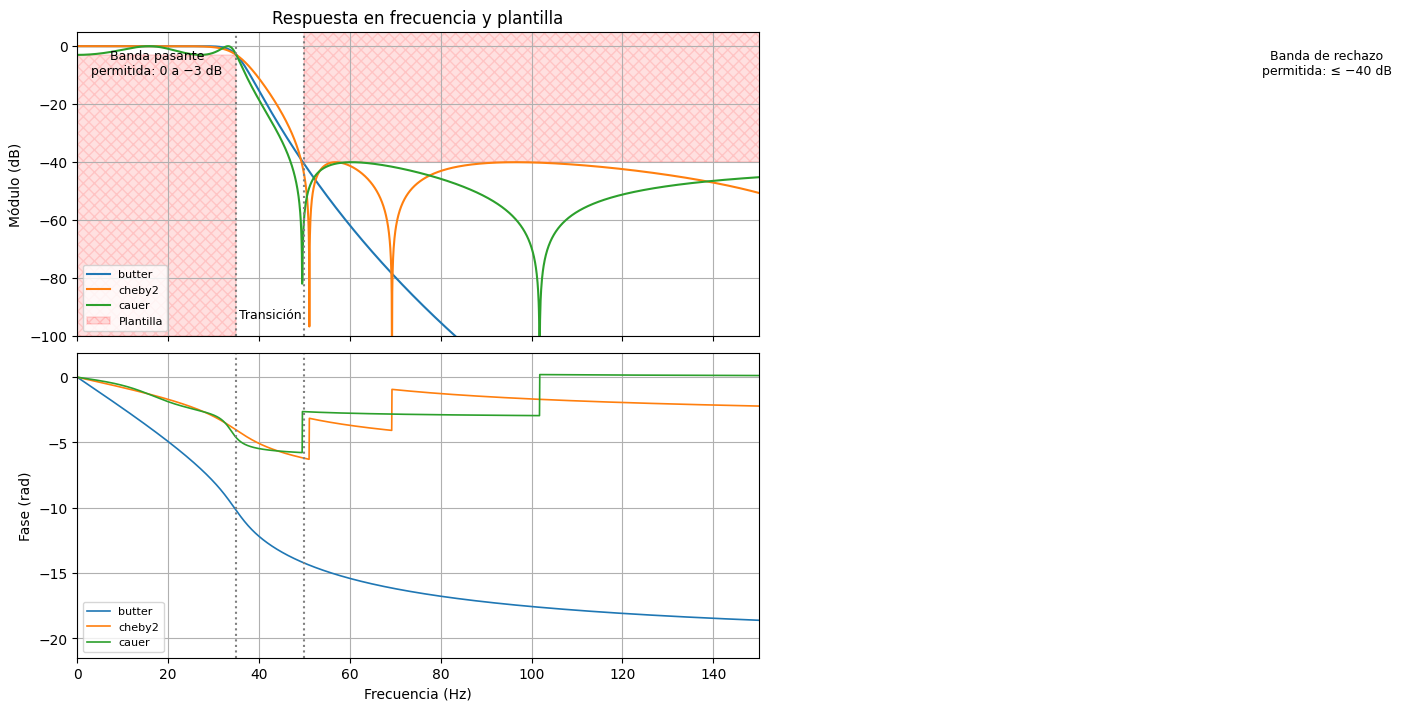

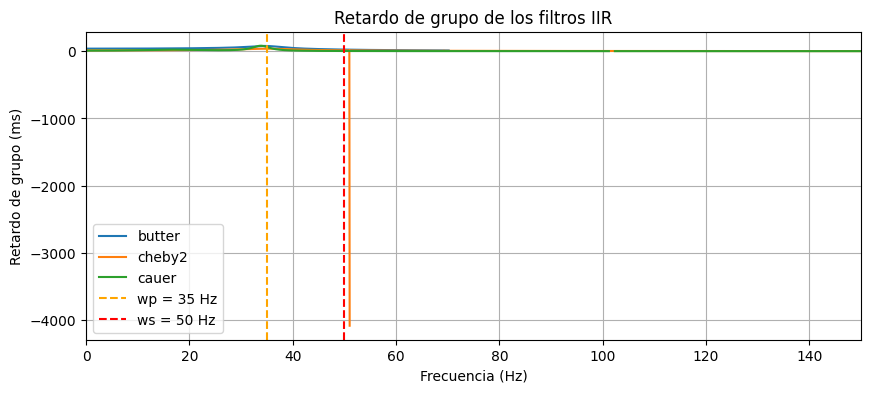

In [146]:
fig_n_axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)
fig_ret, ax_ret = plt.subplots(figsize=(10, 4))

calc_resp( sos_butt, 'butter', fig_n_axes, ax_ret )
calc_resp( sos_cheby2, 'cheby2', fig_n_axes, ax_ret )
calc_resp( sos_cauer, 'cauer', fig_n_axes, ax_ret )

# Ploteo de la plantilla
(fig, (ax_mod, ax_fase)) = fig_n_axes

# Banda pasante: zona no permitida por debajo de -ripple
rect_pasante = Rectangle(
    (0, y_min), wp, -ripple - y_min,
    facecolor="red", alpha=0.12,
    edgecolor="red", hatch="xxx", linewidth=1.2 , label = 'Plantilla'
)
ax_mod.add_patch(rect_pasante)

# Banda de rechazo: zona no permitida por encima de -att
rect_rechazo = Rectangle(
    (ws, -att), fs_ecg / 2 - ws, y_max + att,
    facecolor="red", alpha=0.12,
    edgecolor="red", hatch="xxx", linewidth=1.2
)
ax_mod.add_patch(rect_rechazo)

for ax in (ax_mod, ax_fase):
    ax.axvline(wp, color="gray", linestyle=":")
    ax.axvline(ws, color="gray", linestyle=":")

# Etiquetas de zonas
ax_mod.text(wp / 2, y_max - 6, "Banda pasante\npermitida: 0 a −3 dB",
            ha="center", va="top", fontsize=9)
ax_mod.text((ws + fs_ecg / 2) / 2, y_max - 6,
            "Banda de rechazo\npermitida: ≤ −40 dB",
            ha="center", va="top", fontsize=9)
ax_mod.text((wp + ws) / 2, y_min + 5, "Transición",
            ha="center", va="bottom", fontsize=9)

ax_mod.legend(loc="lower left", fontsize=8)
ax_fase.legend(loc="lower left", fontsize=8)

# Zoom en la zona de interés (se ve mejor la transición)
ax_mod.set_xlim(0, 150)

# Retardo de grupo
ax_ret.axvline(wp, color="orange", linestyle="--", label=f"wp = {wp} Hz")
ax_ret.axvline(ws, color="red", linestyle="--", label=f"ws = {ws} Hz")
ax_ret.set_xlim(0, 150)
ax_ret.set_xlabel("Frecuencia (Hz)")
ax_ret.set_ylabel("Retardo de grupo (ms)")
ax_ret.set_title("Retardo de grupo de los filtros IIR")
ax_ret.grid(True)
ax_ret.legend()

plt.show()

### Análisis del retardo de grupo

| Filtro | Retardo en baja frecuencia | Pico (cerca de $w_p = 35$ Hz) |
|---|---|---|
| Butterworth | ~38 ms | ~78 ms |
| Chebyshev II | ~12 ms | ~36 ms |
| Cauer | ~8 ms | ~81 ms (pico más angosto) |

- Los tres filtros IIR tienen **retardo no constante**: es máximo en el borde de la banda de paso. Por eso, además de demorar la señal, la **distorsionan** (las componentes cercanas a 35 Hz se atrasan más que las de baja frecuencia).
- Butterworth necesita orden 14 para cumplir la plantilla, y por eso es el que más demora.
- Los saltos verticales que aparecen en la banda de rechazo (por ejemplo en Chebyshev II cerca de 51 Hz) **no son retardo real**: coinciden con los ceros de transmisión del filtro, donde la fase salta $\pi$ y su derivada da un pico. Son un artefacto del cálculo.

## Respuesta al impulso

Se usa `sosfiltfilt` (filtrado ida y vuelta), por lo que la respuesta resultante tiene **fase cero**: queda centrada en $n = 0$ y, como el impulso está en $n = 0$, se ve solo su mitad derecha. Por eso se ubica el impulso en el centro del vector.

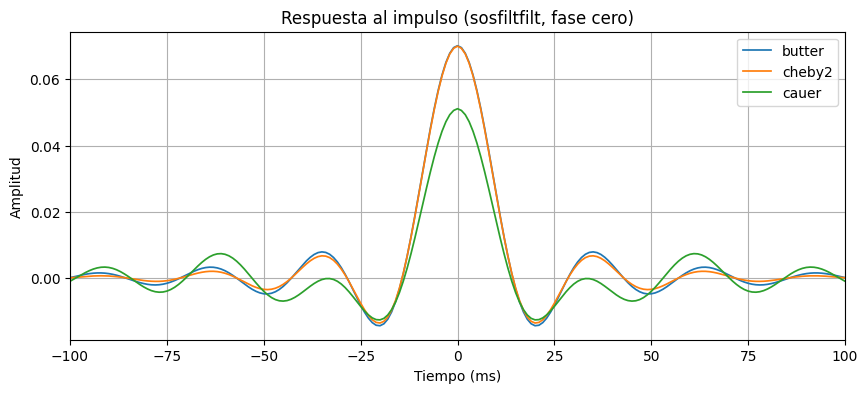

In [147]:
N_imp = 1000
delta_k = sig.unit_impulse(N_imp, idx='mid')
t_imp = (np.arange(N_imp) - N_imp // 2) / fs_ecg * 1000  # ms

resp_imp_butt = sig.sosfiltfilt(sos_butt, delta_k)
resp_imp_cheby2 = sig.sosfiltfilt(sos_cheby2, delta_k)
resp_imp_cauer = sig.sosfiltfilt(sos_cauer, delta_k)

plt.figure(figsize=(10, 4))
plt.plot(t_imp, resp_imp_butt, linewidth=1.25, label= 'butter' )
plt.plot(t_imp, resp_imp_cheby2, linewidth=1.25, label= 'cheby2' )
plt.plot(t_imp, resp_imp_cauer, linewidth=1.25, label= 'cauer' )
plt.xlim(-100, 100)
plt.xlabel("Tiempo (ms)")
plt.ylabel("Amplitud")
plt.title("Respuesta al impulso (sosfiltfilt, fase cero)")
plt.grid(True)
plt.legend()
plt.show()

### Respuesta al impulso causal (`sosfilt`)

Filtrando en una sola pasada se ve la respuesta al impulso real de cada filtro: empieza en $n = 0$ y su "centro de masa" está corrido aproximadamente el retardo de grupo (Butterworth arranca más tarde y tiene el pico más atrasado).

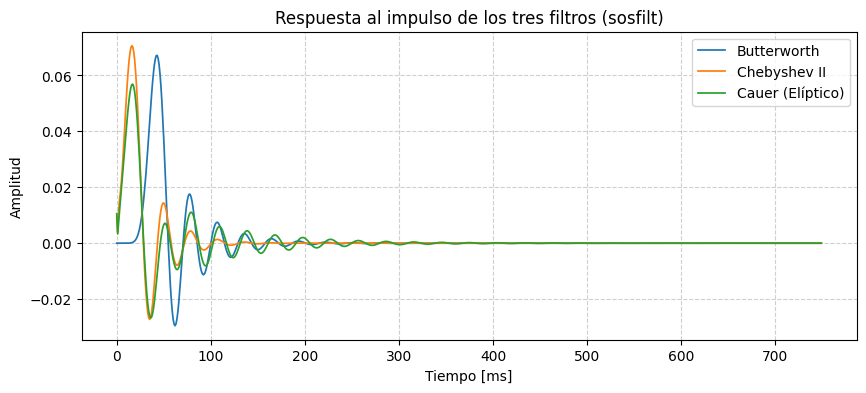

In [148]:
N_imp = 750
delta_k = sig.unit_impulse(N_imp)
t_imp = np.arange(N_imp) / fs_ecg * 1000  # ms

plt.figure(figsize=(10, 4))
plt.plot(t_imp, sig.sosfilt(sos_butt, delta_k), linewidth=1.25, label='Butterworth')
plt.plot(t_imp, sig.sosfilt(sos_cheby2, delta_k), linewidth=1.25, label='Chebyshev II')
plt.plot(t_imp, sig.sosfilt(sos_cauer, delta_k), linewidth=1.25, label='Cauer (Elíptico)')
plt.xlabel('Tiempo [ms]')
plt.ylabel('Amplitud')
plt.title('Respuesta al impulso de los tres filtros (sosfilt)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## Aplicación del filtro al ECG

Como en clase, se filtra con `sosfilt` (filtrado **causal**, una sola pasada). Así se ve el efecto real de cada filtro: la demora (retardo de grupo) y la distorsión de fase en el complejo QRS.

In [149]:
# Aseguro que la señal sea un vector unidimensional
ecg = np.asarray(ecg_one_lead).squeeze()

ecg_filt_butt = sig.sosfilt(sos_butt, ecg)
ecg_filt_cheb2 = sig.sosfilt(sos_cheby2, ecg)
ecg_filt_cauer = sig.sosfilt(sos_cauer, ecg)

demora = 0

## Diseño de filtros FIR

Misma plantilla ($w_p = 35$ Hz, $w_s = 50$ Hz, $G_{pass} = 3$ dB, $G_{stop} = 40$ dB), con dos métodos:

- **Ventana (Kaiser) con `firwin2`:** se le pasa la respuesta deseada punto por punto: `frecs = [0, fc, fc, fs/2]`, `gananc = [1, 1, 0, 0]`, con un **salto en el medio de la transición** ($f_c = 42.5$ Hz). `kaiserord` da el $\beta$ de la ventana según la atenuación, y se busca la menor cantidad de coeficientes que cumple la plantilla.

  ¿Por qué no `[0, wp, ws, fs/2]`? Porque la ventana "ensancha" cualquier transición en el ancho de su lóbulo principal: si la rampa ideal ya termina justo en $w_s$, el filtro resultante todavía no atenuó lo suficiente ahí. Con la plantilla de 40 dB no se llega a cumplir ni con 499 coeficientes. Poniendo el salto en el medio, la transición que genera la ventana queda repartida entre $w_p$ y $w_s$.
- **Parks-McClellan (`remez`):** equiripple; se busca la menor cantidad de coeficientes que cumple la plantilla.

Se usa siempre una cantidad **impar** de coeficientes (FIR tipo I), con fase lineal y una demora entera.

In [150]:
def cumple_plantilla(b):
    f, h = sig.freqz(b, worN=8192, fs=fs_ecg)
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    return modulo_db[f <= wp].min() >= -ripple and modulo_db[f >= ws].max() <= -att

# --- Ventana de Kaiser (firwin2): respuesta deseada punto por punto ---
fc = (wp + ws) / 2   # salto en el medio de la transición
frecs = [0, fc, fc, fs_ecg / 2]
gananc = [1, 1, 0, 0]
_, beta = sig.kaiserord(att, (ws - wp) / (fs_ecg / 2))
for numtaps_win in range(11, 501, 2):
    b_win = sig.firwin2(numtaps_win, frecs, gananc, window=('kaiser', beta), fs=fs_ecg)
    if cumple_plantilla(b_win):
        break

# --- Parks-McClellan: menor cantidad (impar) de coeficientes que cumple ---
for numtaps_remez in range(11, 501, 2):
    b_remez = sig.remez(numtaps_remez, [0, wp, ws, fs_ecg / 2], [1, 0], weight=[1, 10], fs=fs_ecg)
    if cumple_plantilla(b_remez):
        break

for nombre, b in [('FIR window', b_win), ('FIR remez', b_remez)]:
    print(f'{nombre}: {len(b)} coeficientes, cumple plantilla: {cumple_plantilla(b)}')


FIR window: 141 coeficientes, cumple plantilla: True
FIR remez: 95 coeficientes, cumple plantilla: True


### Análisis de un FIR: `freqz`

Un FIR se define por sus coeficientes $b$ (la respuesta al impulso) con denominador $a = 1$, así que se analiza con `sig.freqz(b, 1)` en lugar de `freqz_sos` (no hay secciones de segundo orden).

In [151]:
def calc_resp_fir( b, leg_str, fig_n_axes, ax_ret):

    # Respuesta en frecuencia del FIR: H(z) = B(z) / 1
    f, h = sig.freqz(b, 1, worN=8192, fs=fs_ecg)

    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))

    # Retardo de grupo: -d(fase)/d(omega), en segundos
    omega = 2 * np.pi * f
    retardo_s = -np.gradient(fase_rad, omega)
    retardo_s_plot = np.where(modulo_db > -80, retardo_s, np.nan)

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    ax_mod.plot(f, modulo_db, linewidth=1.5, label= leg_str )
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)

    ax_fase.plot(f, fase_rad, label= leg_str, linewidth=1.2)
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)

    ax_ret.plot(f, retardo_s_plot * 1000, label= leg_str)  # en ms

### Respuesta de los FIR + plantilla

El retardo de grupo de un FIR de fase lineal es **constante**: $\tau = \dfrac{N-1}{2}$ muestras.

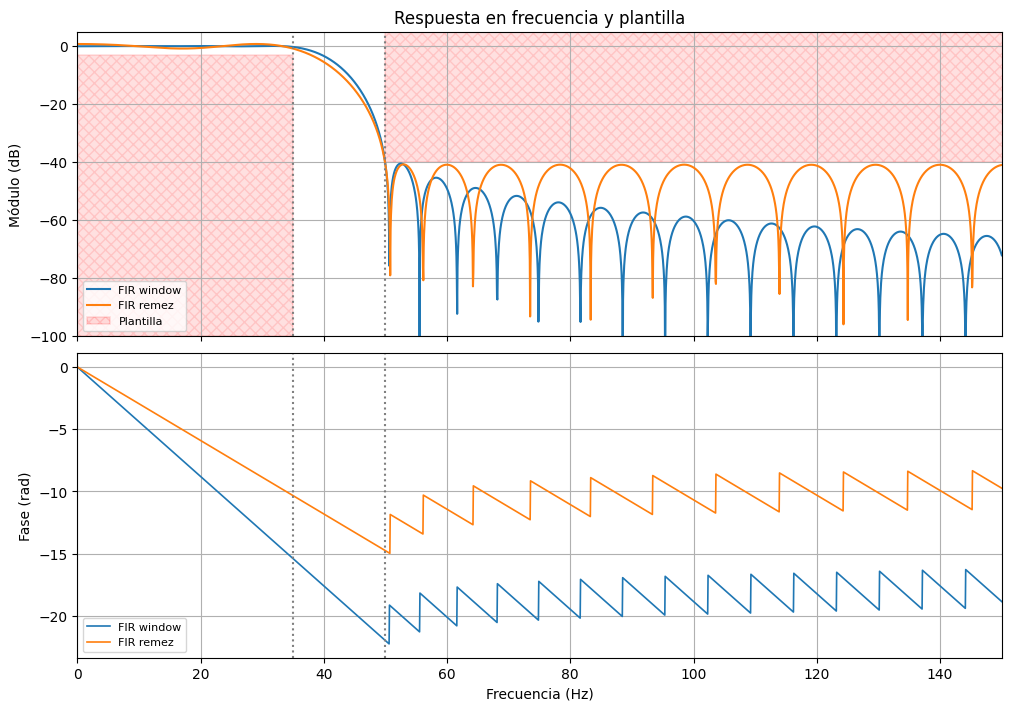

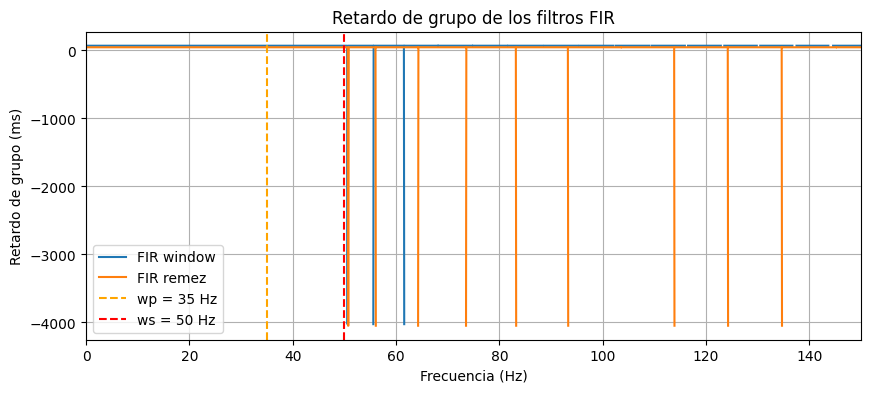

In [152]:
fig_n_axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)
fig_ret, ax_ret = plt.subplots(figsize=(10, 4))

calc_resp_fir( b_win, 'FIR window', fig_n_axes, ax_ret )
calc_resp_fir( b_remez, 'FIR remez', fig_n_axes, ax_ret )

(fig, (ax_mod, ax_fase)) = fig_n_axes

ax_mod.add_patch(Rectangle((0, y_min), wp, -ripple - y_min,
                           facecolor="red", alpha=0.12, edgecolor="red",
                           hatch="xxx", linewidth=1.2, label='Plantilla'))
ax_mod.add_patch(Rectangle((ws, -att), fs_ecg / 2 - ws, y_max + att,
                           facecolor="red", alpha=0.12, edgecolor="red",
                           hatch="xxx", linewidth=1.2))
for ax in (ax_mod, ax_fase):
    ax.axvline(wp, color="gray", linestyle=":")
    ax.axvline(ws, color="gray", linestyle=":")
ax_mod.set_xlim(0, 150)
ax_mod.legend(loc="lower left", fontsize=8)
ax_fase.legend(loc="lower left", fontsize=8)

ax_ret.axvline(wp, color="orange", linestyle="--", label=f"wp = {wp} Hz")
ax_ret.axvline(ws, color="red", linestyle="--", label=f"ws = {ws} Hz")
ax_ret.set_xlim(0, 150)
ax_ret.set_xlabel("Frecuencia (Hz)")
ax_ret.set_ylabel("Retardo de grupo (ms)")
ax_ret.set_title("Retardo de grupo de los filtros FIR")
ax_ret.grid(True)
ax_ret.legend()

plt.show()

### Demora de los FIR

Como el retardo es constante, la demora se puede compensar exactamente desplazando la salida $\dfrac{N-1}{2}$ muestras. Se verifica comparándola con el retardo de grupo calculado en la banda de paso.

In [153]:
demora_win = (len(b_win) - 1) // 2
demora_remez = (len(b_remez) - 1) // 2

for nombre, b, demora_fir in [('FIR window', b_win, demora_win), ('FIR remez', b_remez, demora_remez)]:
    w_gd, gd = sig.group_delay((b, 1), w=np.linspace(1, wp, 100), fs=fs_ecg)
    print(f'{nombre}: (N-1)/2 = {demora_fir} muestras = {demora_fir / fs_ecg * 1000:.0f} ms | '
          f'retardo de grupo medido en banda de paso: {gd.mean():.2f} muestras')

ecg_filt_win = sig.lfilter(b_win, 1, ecg)
ecg_filt_remez = sig.lfilter(b_remez, 1, ecg)

FIR window: (N-1)/2 = 70 muestras = 70 ms | retardo de grupo medido en banda de paso: 70.00 muestras
FIR remez: (N-1)/2 = 47 muestras = 47 ms | retardo de grupo medido en banda de paso: 47.00 muestras


## Regiones de interés

Se grafican tramos del ECG original y filtrado. Para cada región se arma el vector de índices `zoom_region`, limitado entre $0$ y la cantidad de muestras.

Los FIR se grafican **compensando su demora** (`demora_win`, `demora_remez`), por eso quedan alineados con el ECG original; los IIR se grafican sin compensar (`demora = 0`).

In [154]:
cant_muestras = ecg_one_lead.shape[0]

# Señales filtradas a comparar: (etiqueta, señal, demora en muestras)
filtradas_causal = [
    ('Butter', ecg_filt_butt, demora),
    ('Cheby2', ecg_filt_cheb2, demora),
    ('Cauer', ecg_filt_cauer, demora),
    ('FIR Window', ecg_filt_win, demora_win),
    ('FIR Remez', ecg_filt_remez, demora_remez),
]

def plot_regiones(regs_interes, filtradas, titulo='ECG filtering example'):
    for ii in regs_interes:

        # intervalo limitado de 0 a cant_muestras
        zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

        plt.figure(figsize=(10, 4))
        plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
        for etiqueta, y, dem in filtradas:
            plt.plot(zoom_region, y[zoom_region + dem], label=etiqueta)

        plt.title(titulo + ' from ' + str(ii[0]) + ' to ' + str(ii[1]))
        plt.ylabel('Adimensional')
        plt.xlabel('Muestras (#)')

        axes_hdl = plt.gca()
        axes_hdl.legend()
        axes_hdl.set_yticks(())
        axes_hdl.grid(True)

        plt.show()

### Regiones de interés con ruido

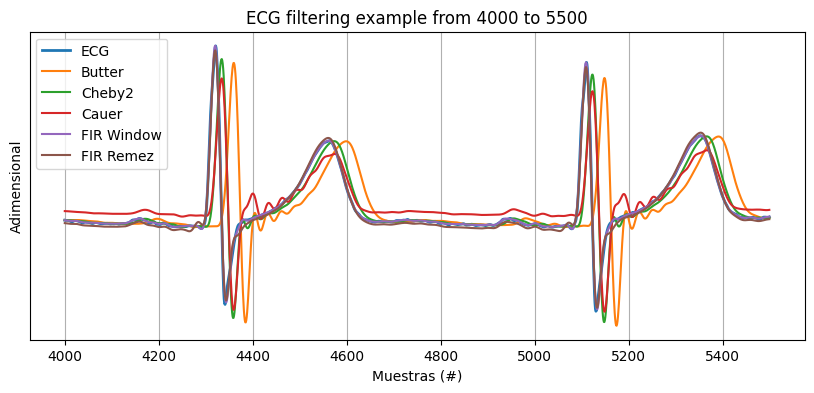

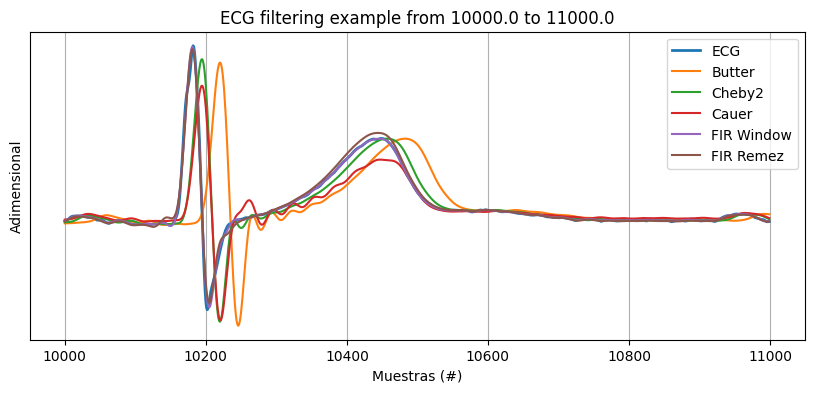

In [155]:
regs_interes = (
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        )

plot_regiones(regs_interes, filtradas_causal)

### Regiones de interés sin ruido

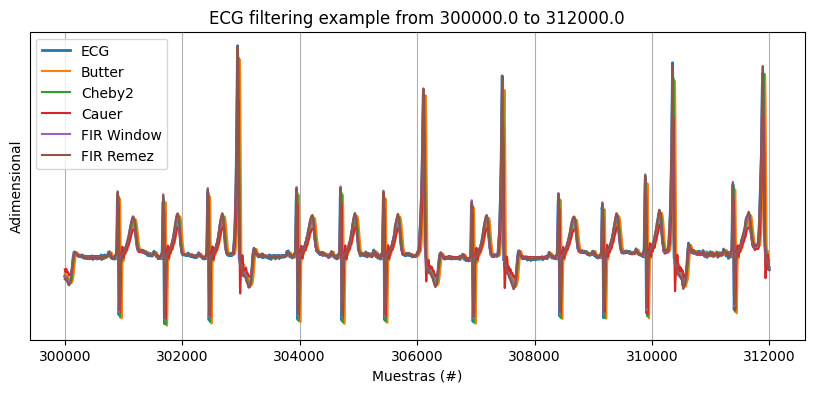

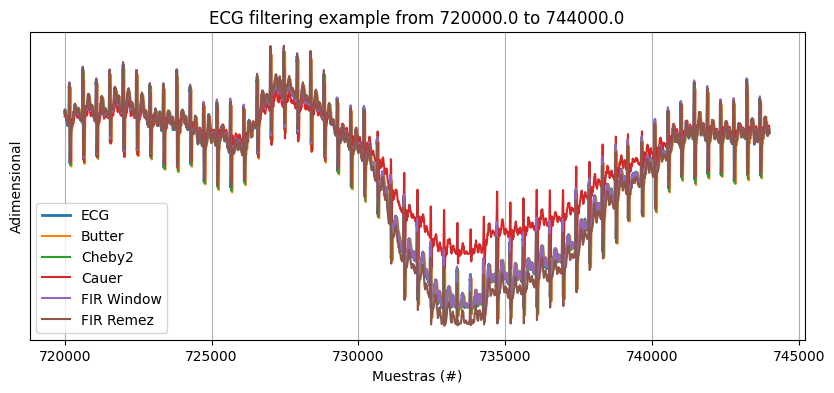

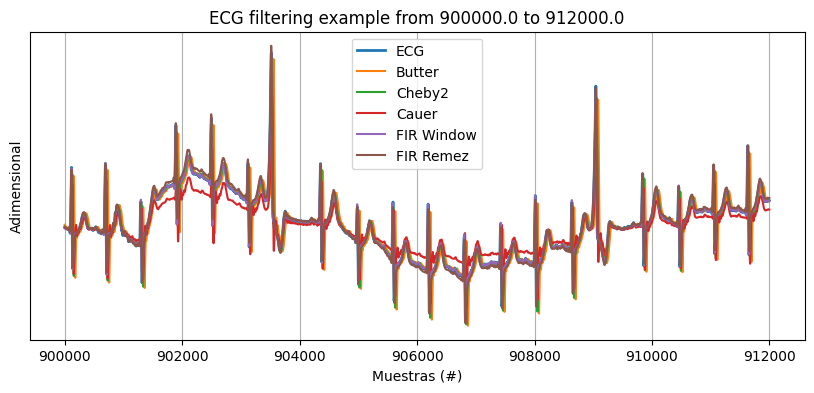

In [156]:
regs_interes = (
        np.array([5, 5.2]) * 60 * fs_ecg,     # minutos a muestras
        np.array([12, 12.4]) * 60 * fs_ecg,   # minutos a muestras
        np.array([15, 15.2]) * 60 * fs_ecg,   # minutos a muestras
        )

plot_regiones(regs_interes, filtradas_causal)

### Verificación de la demora sobre un latido

Se mide la posición del pico R en el ECG original y en cada señal filtrada (IIR sin compensar). La diferencia debería coincidir con el retardo de grupo en baja frecuencia del gráfico anterior: el contenido del latido está mayormente por debajo de 35 Hz.

Butterworth: pico R en 4359 -> demora 38 ms
Chebyshev II: pico R en 4334 -> demora 13 ms
Cauer: pico R en 4334 -> demora 13 ms


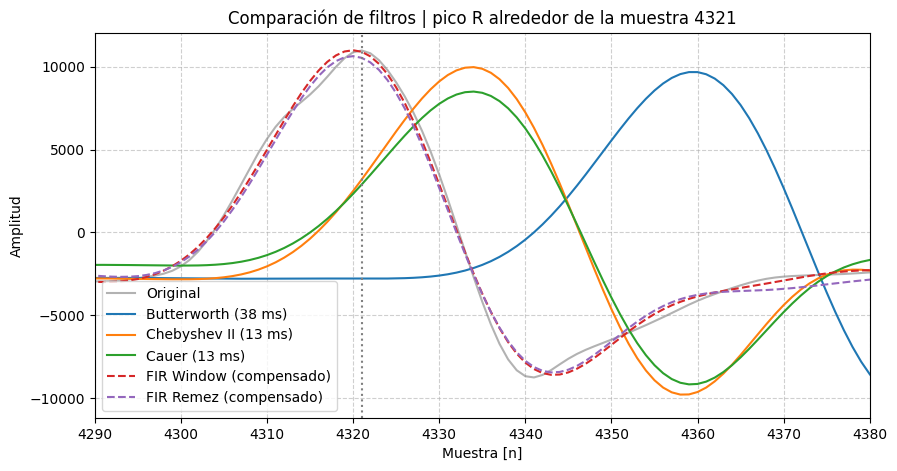

In [157]:
zoom_region = np.arange(4250, 4450)

pico_original = zoom_region[np.argmax(ecg_one_lead[zoom_region])]

plt.figure(figsize=(10, 5))
plt.plot(zoom_region, ecg_one_lead[zoom_region], color='gray', alpha=0.6, label='Original')

for nombre, y in [('Butterworth', ecg_filt_butt), ('Chebyshev II', ecg_filt_cheb2), ('Cauer', ecg_filt_cauer)]:
    pico = zoom_region[np.argmax(y[zoom_region])]
    demora_ms = (pico - pico_original) / fs_ecg * 1000
    print(f'{nombre}: pico R en {pico} -> demora {demora_ms:.0f} ms')
    plt.plot(zoom_region, y[zoom_region], label=f'{nombre} ({demora_ms:.0f} ms)')

plt.plot(zoom_region, ecg_filt_win[zoom_region + demora_win], '--', label='FIR Window (compensado)')
plt.plot(zoom_region, ecg_filt_remez[zoom_region + demora_remez], '--', label='FIR Remez (compensado)')

plt.axvline(pico_original, color='gray', linestyle=':')
plt.xlim(4290, 4380)
plt.title('Comparación de filtros | pico R alrededor de la muestra 4321')
plt.xlabel('Muestra [n]')
plt.ylabel('Amplitud')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

Las demoras medidas (Butterworth ≈ 38 ms, Chebyshev II ≈ 13 ms, Cauer ≈ 13 ms) coinciden con el retardo de grupo de cada filtro. Los FIR, en cambio, compensados con su demora constante $(N-1)/2$, quedan **alineados** con el original y sin distorsión de fase.

## Filtrado bidireccional (`sosfiltfilt`)

`sosfiltfilt` filtra hacia adelante y hacia atrás, así que la respuesta efectiva es $|H(e^{j\omega})|^2$:

- **Fase cero:** no hay demora ni distorsión de fase (`demora = 0`).
- **El módulo en dB se duplica:** el ripple y la atenuación se suman dos veces.

Por eso, como en clase, cada filtro se diseña con **la mitad** de la plantilla ($G_{pass} = 3/2$ dB, $G_{stop} = 40/2$ dB): al aplicarlo dos veces, la respuesta total cumple la plantilla original.

Órdenes (diseño con la mitad de la plantilla):
  butter: orden 8
  cheby2: orden 4
  cauer: orden 4


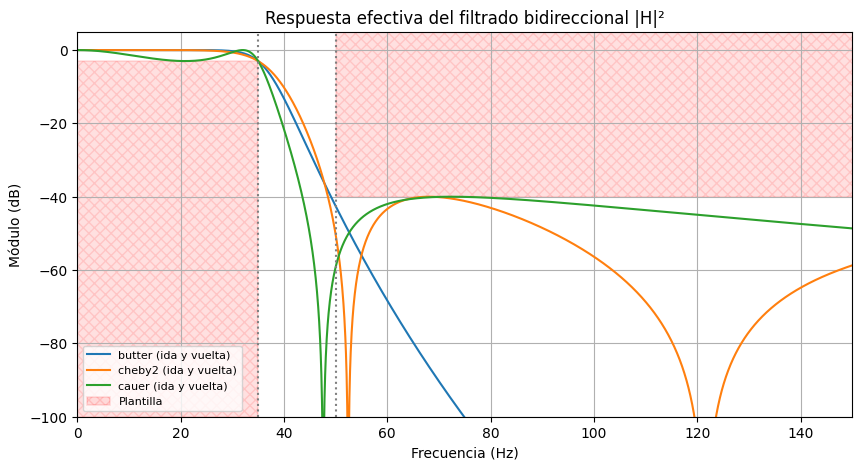

In [158]:
Gpass_bi = Gpass / 2
Gstop_bi = Gstop / 2

sos_butt_bi = sig.iirdesign(wp, ws, Gpass_bi, Gstop_bi, ftype='butter', fs = fs_ecg, output = 'sos')
sos_cheby2_bi = sig.iirdesign(wp, ws, Gpass_bi, Gstop_bi, ftype='cheby2', fs = fs_ecg, output = 'sos')
sos_cauer_bi = sig.iirdesign(wp, ws, Gpass_bi, Gstop_bi, ftype='cauer', fs = fs_ecg, output = 'sos')

print('Órdenes (diseño con la mitad de la plantilla):')
for nombre, sos in [('butter', sos_butt_bi), ('cheby2', sos_cheby2_bi), ('cauer', sos_cauer_bi)]:
    print(f'  {nombre}: orden {2 * sos.shape[0]}')

# Respuesta efectiva del filtrado ida y vuelta: |H|^2  ->  2 * (módulo en dB)
plt.figure(figsize=(10, 5))
for nombre, sos in [('butter', sos_butt_bi), ('cheby2', sos_cheby2_bi), ('cauer', sos_cauer_bi)]:
    f, h = sig.freqz_sos(sos, worN=8192, fs=fs_ecg)
    plt.plot(f, 2 * 20 * np.log10(np.maximum(np.abs(h), 1e-12)), label=nombre + ' (ida y vuelta)')

ax = plt.gca()
ax.add_patch(Rectangle((0, y_min), wp, -ripple - y_min,
                       facecolor="red", alpha=0.12, edgecolor="red",
                       hatch="xxx", linewidth=1.2, label='Plantilla'))
ax.add_patch(Rectangle((ws, -att), fs_ecg / 2 - ws, y_max + att,
                       facecolor="red", alpha=0.12, edgecolor="red",
                       hatch="xxx", linewidth=1.2))
plt.axvline(wp, color="gray", linestyle=":")
plt.axvline(ws, color="gray", linestyle=":")
plt.xlim(0, 150)
plt.ylim(y_min, y_max)
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Módulo (dB)')
plt.title('Respuesta efectiva del filtrado bidireccional |H|²')
plt.grid(True)
plt.legend(loc='lower left', fontsize=8)
plt.show()

In [159]:
ecg_filt_butt_bi = sig.sosfiltfilt(sos_butt_bi, ecg_one_lead)
ecg_filt_cheb2_bi = sig.sosfiltfilt(sos_cheby2_bi, ecg_one_lead)
ecg_filt_cauer_bi = sig.sosfiltfilt(sos_cauer_bi, ecg_one_lead)

filtradas_bidir = [
    ('Butter', ecg_filt_butt_bi, 0),
    ('Cheby2', ecg_filt_cheb2_bi, 0),
    ('Cauer', ecg_filt_cauer_bi, 0),
]

### Regiones de interés con filtrado bidireccional

Ahora los tres IIR quedan **alineados** con el ECG original, sin necesidad de compensar ninguna demora.

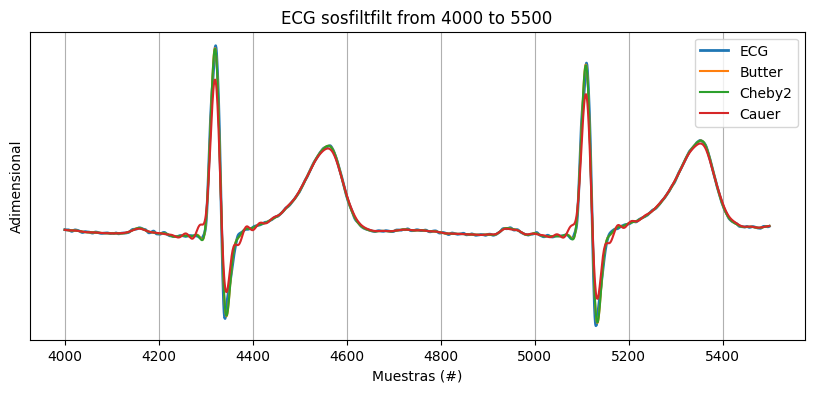

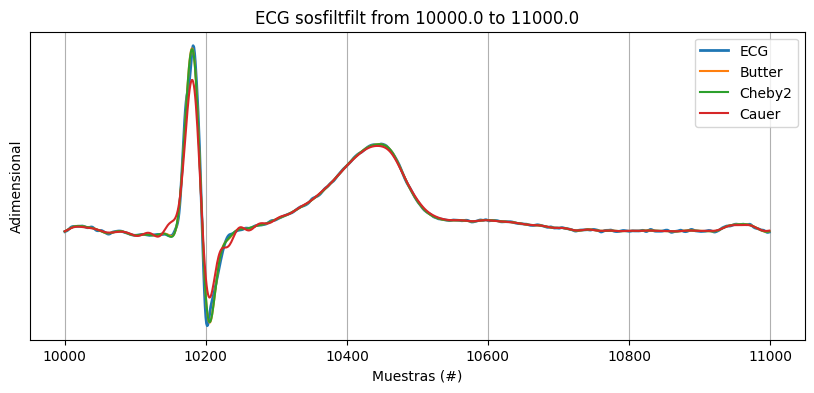

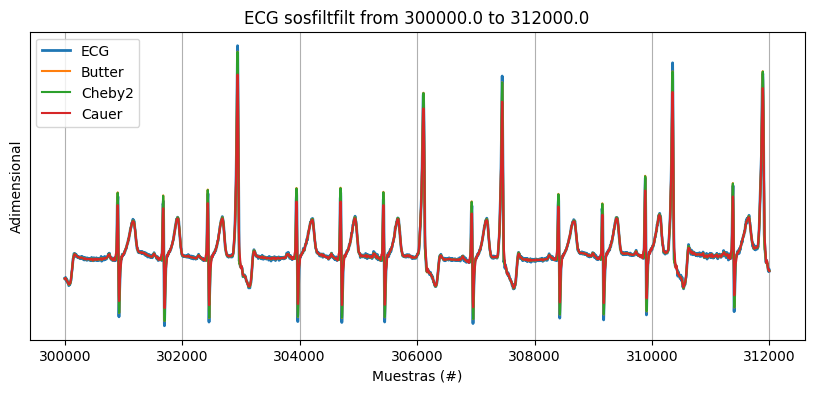

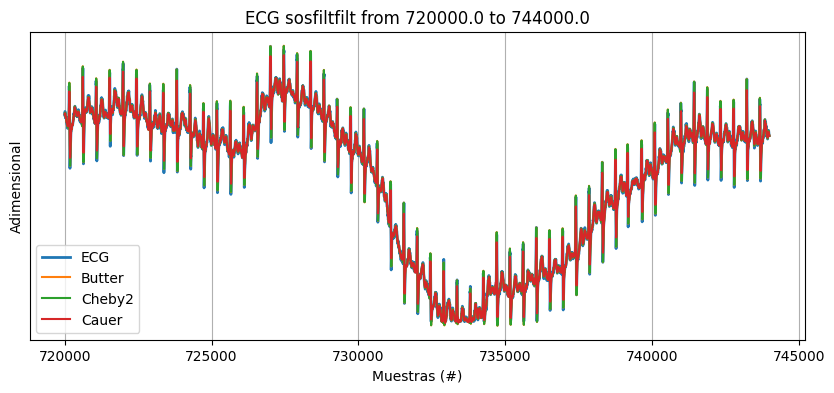

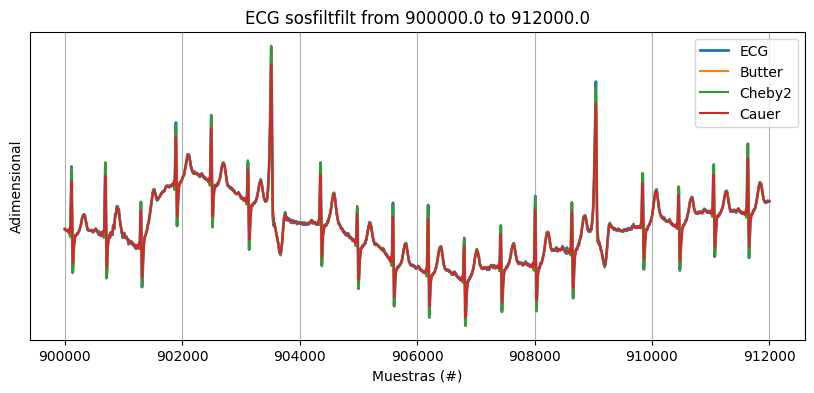

In [136]:
regs_interes = (
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        np.array([5, 5.2]) * 60 * fs_ecg,     # minutos a muestras
        np.array([12, 12.4]) * 60 * fs_ecg,   # minutos a muestras
        np.array([15, 15.2]) * 60 * fs_ecg,   # minutos a muestras
        )

plot_regiones(regs_interes, filtradas_bidir, titulo='ECG sosfiltfilt')

### Atenuación del complejo QRS

En la región 10000–11000 se ve que **Cauer recorta el pico R** y el valle S, mientras que Butterworth y Chebyshev II lo siguen casi perfecto. Se mide la amplitud pico a pico del latido en cada señal:

Butter: 98 % de la amplitud pico a pico original
Cheby2: 97 % de la amplitud pico a pico original
Cauer: 78 % de la amplitud pico a pico original


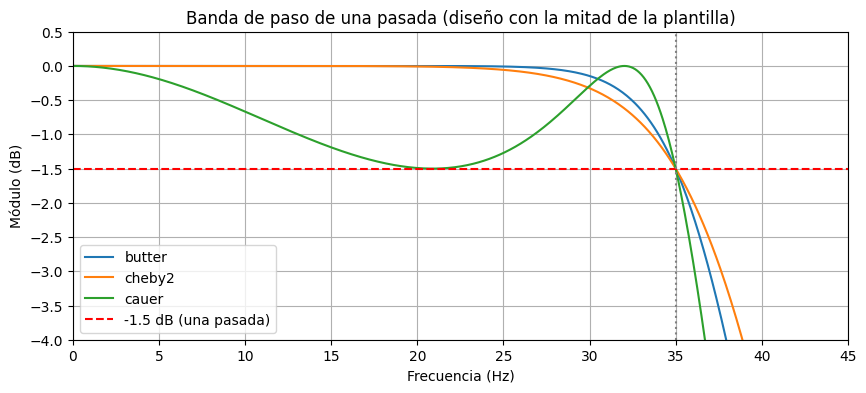

In [137]:
region = slice(10000, 11000)
pp_original = np.ptp(ecg_one_lead[region])

for nombre, y, _ in filtradas_bidir:
    pp = np.ptp(y[region])
    print(f'{nombre}: {pp / pp_original * 100:.0f} % de la amplitud pico a pico original')

# Respuesta de UNA pasada en la banda de paso: dónde atenúa cada filtro
plt.figure(figsize=(10, 4))
for nombre, sos in [('butter', sos_butt_bi), ('cheby2', sos_cheby2_bi), ('cauer', sos_cauer_bi)]:
    f, h = sig.freqz_sos(sos, worN=8192, fs=fs_ecg)
    plt.plot(f, 20 * np.log10(np.maximum(np.abs(h), 1e-12)), label=nombre)
plt.axhline(-Gpass_bi, color='red', linestyle='--', label=f'-{Gpass_bi} dB (una pasada)')
plt.axvline(wp, color='gray', linestyle=':')
plt.xlim(0, 45)
plt.ylim(-4, 0.5)
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Módulo (dB)')
plt.title('Banda de paso de una pasada (diseño con la mitad de la plantilla)')
plt.grid(True)
plt.legend()
plt.show()

- **Butterworth** es máximamente plano y **Chebyshev II** tiene el ripple solo en la banda de rechazo: en la banda de paso casi no atenúan, por eso conservan el QRS (97–98 %).
- **Cauer** tiene ripple en la **banda de paso**: llega a $-1.5$ dB por pasada, o sea $-3$ dB en el filtrado ida y vuelta. Como el QRS tiene mucho contenido entre 10 y 35 Hz, el pico R queda recortado (78 % de la amplitud pico a pico).
- Los tres cumplen la plantilla, pero para ECG importa **dónde** se gasta el ripple permitido: conviene un filtro plano en la banda de paso.

## FIR para la plantilla de clase ($G_{pass} = 1.5$ dB, $G_{stop} = 20$ dB)

Se diseñan FIR que cumplan la plantilla del gráfico de clase: $w_p = 35$ Hz, $w_s = 50$ Hz, ripple $\le 1.5$ dB y atenuación $\ge 20$ dB.

**¿Cómo se evalúa (aplica) un FIR?** Es una **convolución** de la señal con $b$. Hay dos opciones:
- `lfilter(b, 1, x)`: una sola pasada, demora constante $(N-1)/2$ que se compensa desplazando la salida.
- `filtfilt(b, 1, x)`: fase cero, pero hay que **predistorsionar la plantilla** (la mitad en dB) porque el módulo se aplica dos veces.

Vamos con **`lfilter`**, así que el FIR tiene que cumplir la plantilla tal cual. Para analizarlo se usa **`freqz`** (no `freqz_sos`).

In [138]:
ripple_fir = Gpass_bi   # 1.5 dB
att_fir = Gstop_bi      # 20 dB

def cumple(b, rip, at):
    f, h = sig.freqz(b, 1, worN=8192, fs=fs_ecg)
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    return modulo_db[f <= wp].min() >= -rip and modulo_db[f >= ws].max() <= -at

# --- Ventana de Kaiser (firwin2, mismos frecs/gananc): menor cantidad (impar) de coeficientes que cumple ---
_, beta2 = sig.kaiserord(att_fir, (ws - wp) / (fs_ecg / 2))
for numtaps_win2 in range(11, 501, 2):
    b_win2 = sig.firwin2(numtaps_win2, frecs, gananc,
                         window=('kaiser', beta2), fs=fs_ecg)
    if cumple(b_win2, ripple_fir, att_fir):
        break

# --- Parks-McClellan (equiripple) ---
for numtaps_remez2 in range(11, 501, 2):
    b_remez2 = sig.remez(numtaps_remez2, [0, wp, ws, fs_ecg / 2], [1, 0], weight=[1, 5], fs=fs_ecg)
    if cumple(b_remez2, ripple_fir, att_fir):
        break

for nombre, b in [('FIR window', b_win2), ('FIR remez', b_remez2)]:
    print(f'{nombre}: {len(b)} coeficientes -> demora (N-1)/2 = {(len(b) - 1) // 2} muestras, '
          f'cumple plantilla: {cumple(b, ripple_fir, att_fir)}')

FIR window: 67 coeficientes -> demora (N-1)/2 = 33 muestras, cumple plantilla: True
FIR remez: 65 coeficientes -> demora (N-1)/2 = 32 muestras, cumple plantilla: True


### Análisis con `freqz` + plantilla

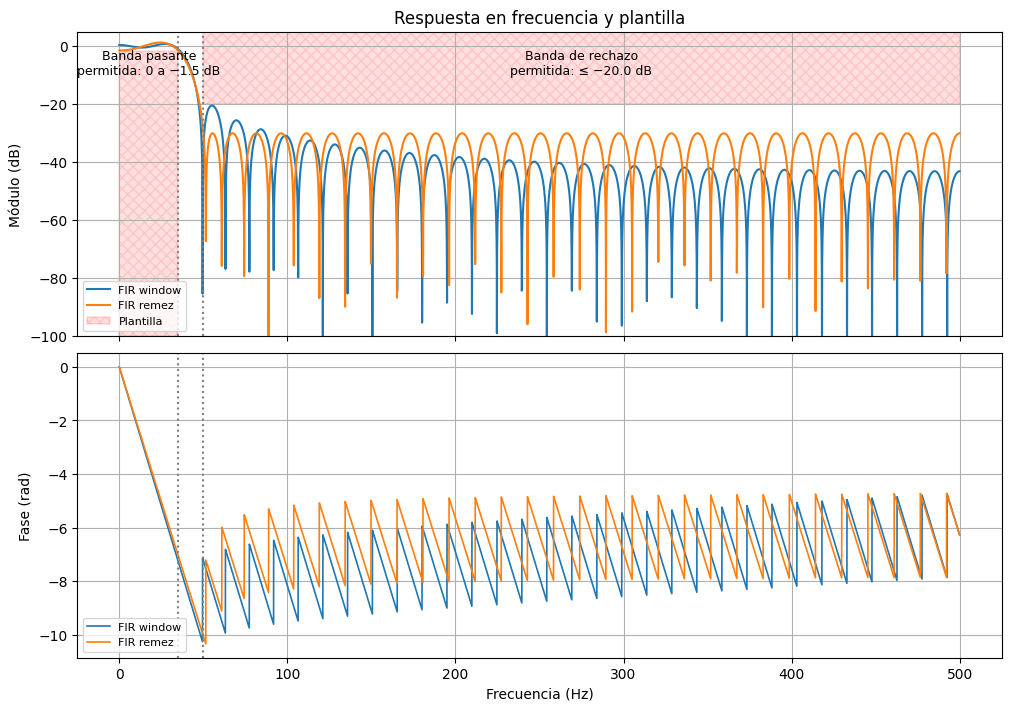

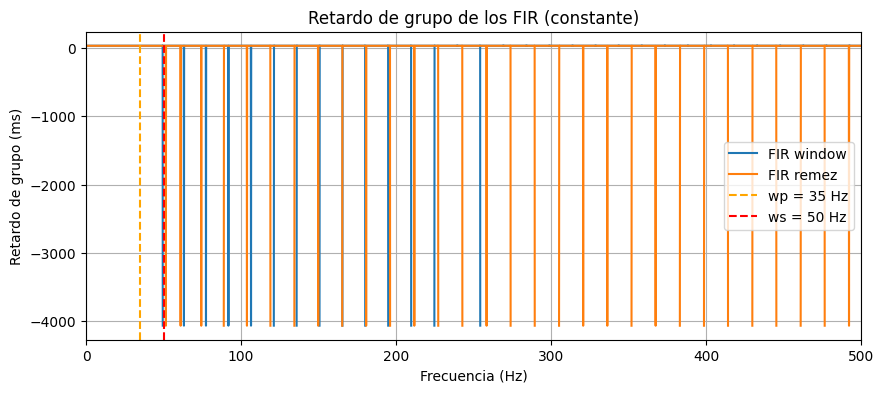

In [139]:
fig_n_axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)
fig_ret, ax_ret = plt.subplots(figsize=(10, 4))

calc_resp_fir( b_win2, 'FIR window', fig_n_axes, ax_ret )
calc_resp_fir( b_remez2, 'FIR remez', fig_n_axes, ax_ret )

(fig, (ax_mod, ax_fase)) = fig_n_axes

ax_mod.add_patch(Rectangle((0, y_min), wp, -ripple_fir - y_min,
                           facecolor="red", alpha=0.12, edgecolor="red",
                           hatch="xxx", linewidth=1.2, label='Plantilla'))
ax_mod.add_patch(Rectangle((ws, -att_fir), fs_ecg / 2 - ws, y_max + att_fir,
                           facecolor="red", alpha=0.12, edgecolor="red",
                           hatch="xxx", linewidth=1.2))
for ax in (ax_mod, ax_fase):
    ax.axvline(wp, color="gray", linestyle=":")
    ax.axvline(ws, color="gray", linestyle=":")
ax_mod.text(wp / 2, y_max - 6, f"Banda pasante\npermitida: 0 a −{ripple_fir} dB",
            ha="center", va="top", fontsize=9)
ax_mod.text((ws + fs_ecg / 2) / 2, y_max - 6, f"Banda de rechazo\npermitida: ≤ −{att_fir} dB",
            ha="center", va="top", fontsize=9)
ax_mod.legend(loc="lower left", fontsize=8)
ax_fase.legend(loc="lower left", fontsize=8)

ax_ret.axvline(wp, color="orange", linestyle="--", label=f"wp = {wp} Hz")
ax_ret.axvline(ws, color="red", linestyle="--", label=f"ws = {ws} Hz")
ax_ret.set_xlim(0, fs_ecg / 2)
ax_ret.set_xlabel("Frecuencia (Hz)")
ax_ret.set_ylabel("Retardo de grupo (ms)")
ax_ret.set_title("Retardo de grupo de los FIR (constante)")
ax_ret.grid(True)
ax_ret.legend()

plt.show()

### Aplicación al ECG con `lfilter`

`lfilter(b, 1, x)` es la convolución de $x$ con $b$. La salida queda atrasada $(N-1)/2$ muestras, y como el retardo es constante se compensa exacto desplazando la señal.

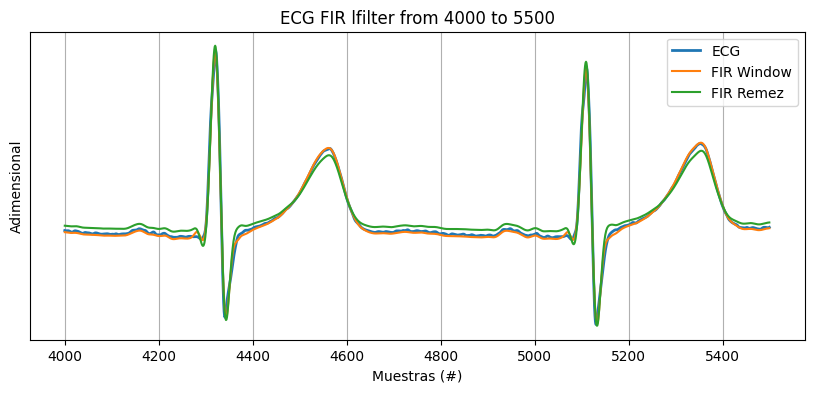

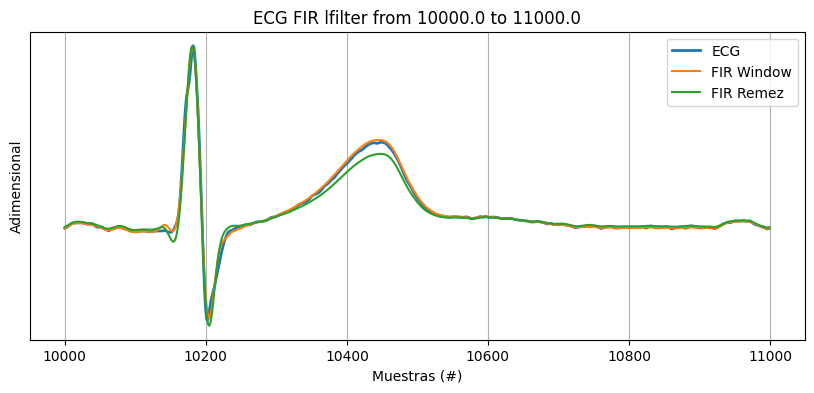

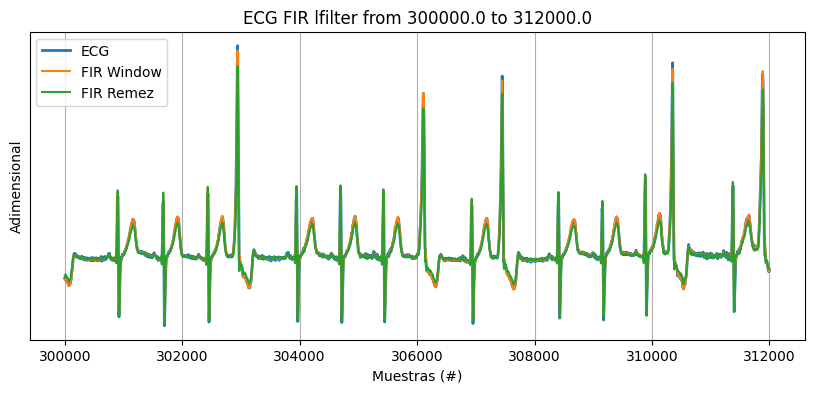

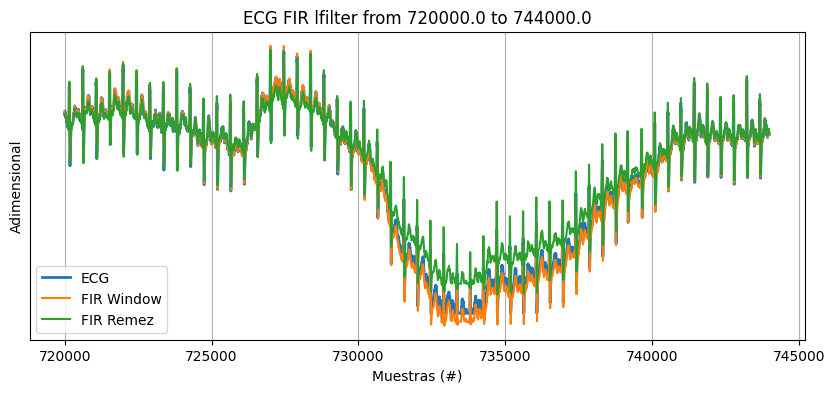

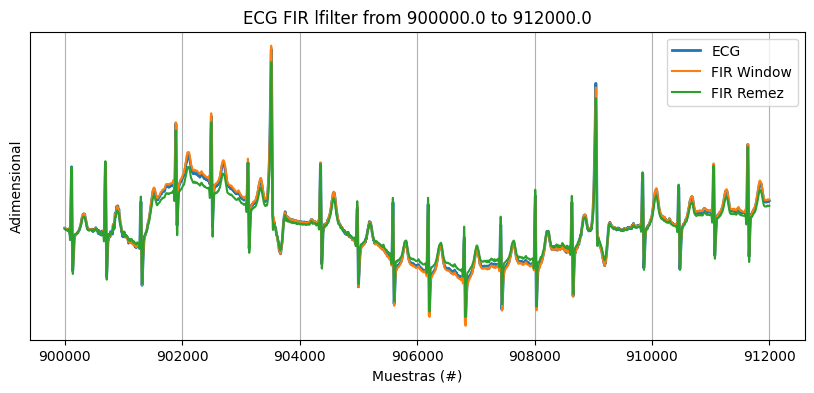

In [140]:
ecg_filt_win2 = sig.lfilter(b_win2, 1, ecg_one_lead)
ecg_filt_remez2 = sig.lfilter(b_remez2, 1, ecg_one_lead)

demora_win2 = (len(b_win2) - 1) // 2
demora_remez2 = (len(b_remez2) - 1) // 2

filtradas_fir = [
    ('FIR Window', ecg_filt_win2, demora_win2),
    ('FIR Remez', ecg_filt_remez2, demora_remez2),
]

regs_interes = (
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        np.array([5, 5.2]) * 60 * fs_ecg,     # minutos a muestras
        np.array([12, 12.4]) * 60 * fs_ecg,   # minutos a muestras
        np.array([15, 15.2]) * 60 * fs_ecg,   # minutos a muestras
        )

plot_regiones(regs_interes, filtradas_fir, titulo='ECG FIR lfilter')

## Efecto de la ventana en `firwin2` (clase)

Como en clase: `firwin2` con los bordes de la plantilla `[0, wp, ws, fs/2]` → `[1, 1, 0, 0]`, **pocos coeficientes** (`taps_win = 7`) y tres ventanas distintas: rectangular (`boxcar`), `hamming` y `blackman`. Se grafican junto a los IIR (diseñados con la mitad de la plantilla para `sosfiltfilt`).

In [141]:
def calc_freq_sos( sos ):
    # Respuesta en frecuencia de un IIR en SOS
    return sig.freqz_sos(sos, worN=8192, fs=fs_ecg)

def calc_freq_fir( bfir ):
    # Respuesta en frecuencia de un FIR: denominador a = 1
    return sig.freqz(bfir, 1, worN=8192, fs=fs_ecg)

def plot_resp( resp_freq, leg_str, fig_n_axes ):
    (f, h) = resp_freq
    (fig, (ax_mod, ax_fase)) = fig_n_axes
    ax_mod.plot(f, 20 * np.log10(np.maximum(np.abs(h), 1e-12)), linewidth=1.5, label=leg_str)
    ax_fase.plot(f, np.unwrap(np.angle(h)), linewidth=1.2, label=leg_str)

def plot_plantilla( fig_n_axes, rip, at ):
    (fig, (ax_mod, ax_fase)) = fig_n_axes
    ax_mod.add_patch(Rectangle((0, y_min), wp, -rip - y_min,
                               facecolor="red", alpha=0.12, edgecolor="red",
                               hatch="xxx", linewidth=1.2, label='Plantilla'))
    ax_mod.add_patch(Rectangle((ws, -at), fs_ecg / 2 - ws, y_max + at,
                               facecolor="red", alpha=0.12, edgecolor="red",
                               hatch="xxx", linewidth=1.2))
    for ax in (ax_mod, ax_fase):
        ax.axvline(wp, color="gray", linestyle=":")
        ax.axvline(ws, color="gray", linestyle=":")
        ax.grid(True)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_mod.legend(loc="lower left", fontsize=8)

def disenar_ventanas( taps_win ):
    return {w: sig.firwin2(taps_win, [0.0, wp, ws, fs_ecg/2], [1.0, 1.0, 0.0, 0.0],
                           window=w, fs=fs_ecg)
            for w in ['boxcar', 'hamming', 'blackman']}

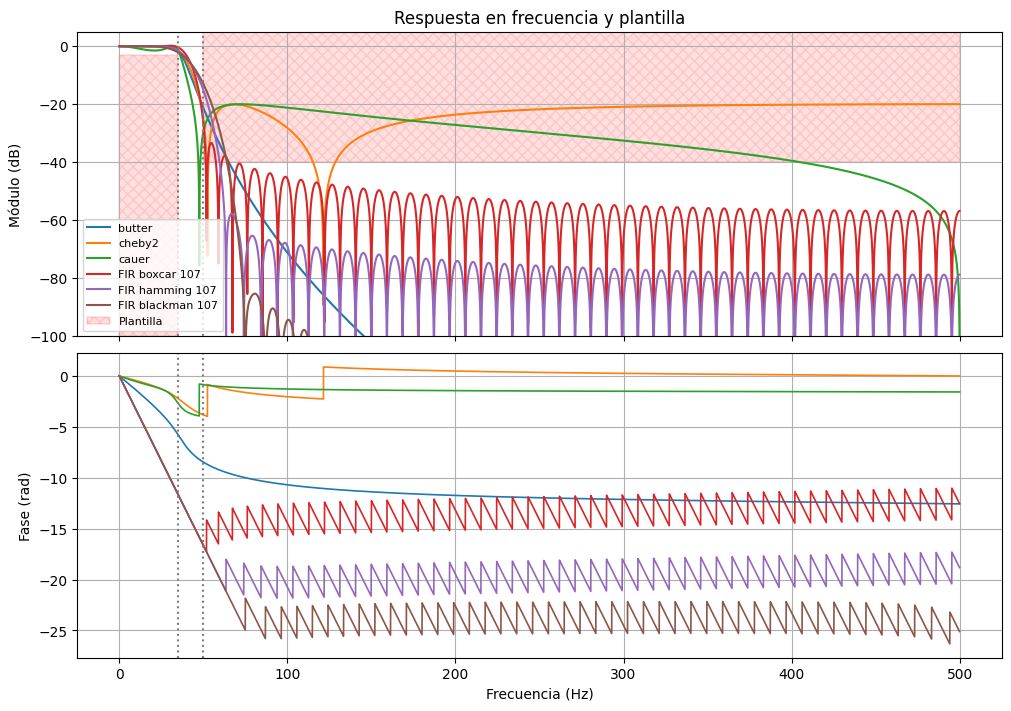

boxcar   : ganancia en 0 Hz =   -0.0 dB | peor caso banda de rechazo =  -26.7 dB
hamming  : ganancia en 0 Hz =    0.0 dB | peor caso banda de rechazo =  -15.2 dB
blackman : ganancia en 0 Hz =    0.0 dB | peor caso banda de rechazo =  -13.1 dB


In [160]:
taps_win = 107
b_ventanas = disenar_ventanas(taps_win)

fig_n_axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)

# IIR (mitad de la plantilla, para sosfiltfilt)
plot_resp( calc_freq_sos(sos_butt_bi), 'butter', fig_n_axes )
plot_resp( calc_freq_sos(sos_cheby2_bi), 'cheby2', fig_n_axes )
plot_resp( calc_freq_sos(sos_cauer_bi), 'cauer', fig_n_axes )

# FIR
for w, b in b_ventanas.items():
    plot_resp( calc_freq_fir(b), f'FIR {w} {taps_win}', fig_n_axes )

plot_plantilla( fig_n_axes, ripple, att )
plt.show()

for w, b in b_ventanas.items():
    f, h = calc_freq_fir(b)
    m = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    print(f'{w:9s}: ganancia en 0 Hz = {m[0]:6.1f} dB | peor caso banda de rechazo = {m[f >= ws].max():6.1f} dB')

**Con 7 coeficientes ninguna ventana cumple la plantilla:**

- **Ganancia en continua menor a 0 dB** (≈ −7 dB boxcar, −14 dB hamming, −16 dB blackman). La respuesta al impulso ideal de un pasabajos de ~42 Hz es una sinc de ~12 ms de ancho de lóbulo principal; con 7 muestras solo entra un pedacito, y la suma de los coeficientes (= ganancia en continua) queda muy por debajo de 1. Las ventanas que achican los extremos (hamming, blackman) la bajan todavía más.
- **No hay transición:** la resolución en frecuencia de un FIR de $N$ coeficientes es del orden de $f_s / N \approx 143$ Hz, mucho más ancha que la transición pedida de 15 Hz.
- **La fase es lineal** (rectas en el gráfico): los saltos son de $\pi$ en los ceros del módulo, no distorsión.

### Comparación de ventanas con más coeficientes

Aumentando `taps_win` se ve el compromiso clásico de las ventanas:
- **boxcar:** el lóbulo principal más angosto (transición más rápida) pero lóbulos laterales altos: la atenuación en la banda de rechazo se estanca en ≈ −26 dB por más coeficientes que se agreguen (fenómeno de Gibbs), así que **nunca** llega a −40 dB.
- **hamming / blackman:** lóbulos laterales mucho más bajos, pero lóbulo principal más ancho: con la plantilla fija en `[wp, ws]`, la transición se "corre" más allá de $w_s$ y en el borde de la banda de rechazo atenúan menos (con 151 coeficientes: −18 dB hamming, −16 dB blackman).

Por eso, en las secciones anteriores, `firwin2` se usó con el salto en el medio de la transición (`[0, fc, fc, fs/2]`) y ventana de Kaiser: así la transición que agrega la ventana queda dentro de $[w_p, w_s]$.

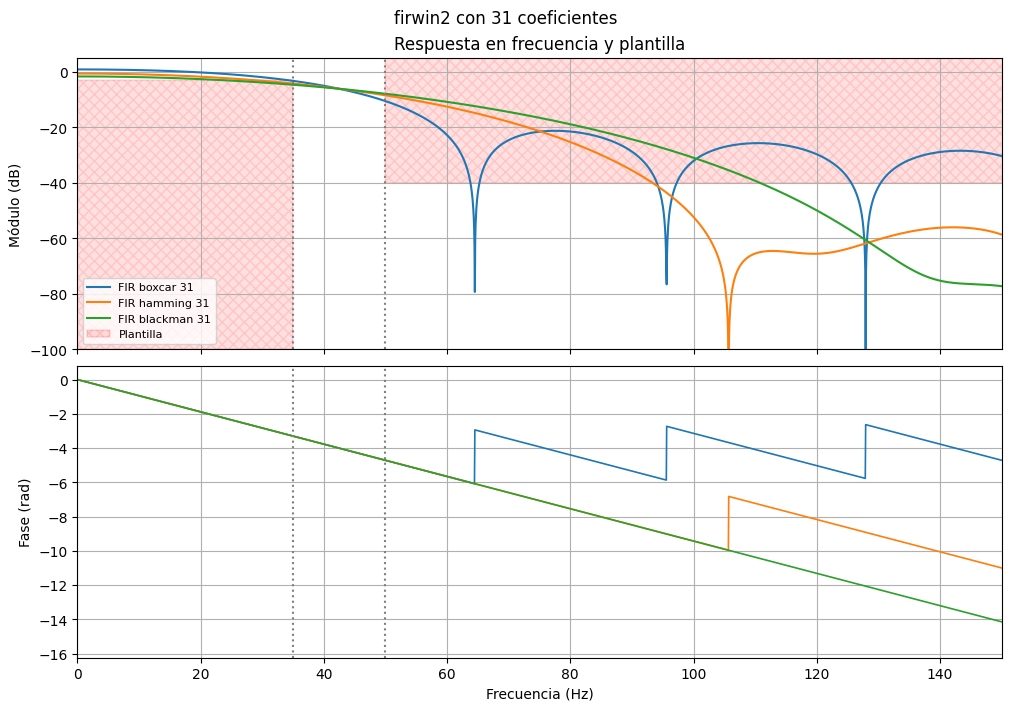

--- 31 coeficientes ---
boxcar   : peor caso banda de paso =  -3.2 dB | peor caso banda de rechazo =  -10.6 dB
hamming  : peor caso banda de paso =  -4.2 dB | peor caso banda de rechazo =   -8.5 dB
blackman : peor caso banda de paso =  -4.6 dB | peor caso banda de rechazo =   -7.9 dB


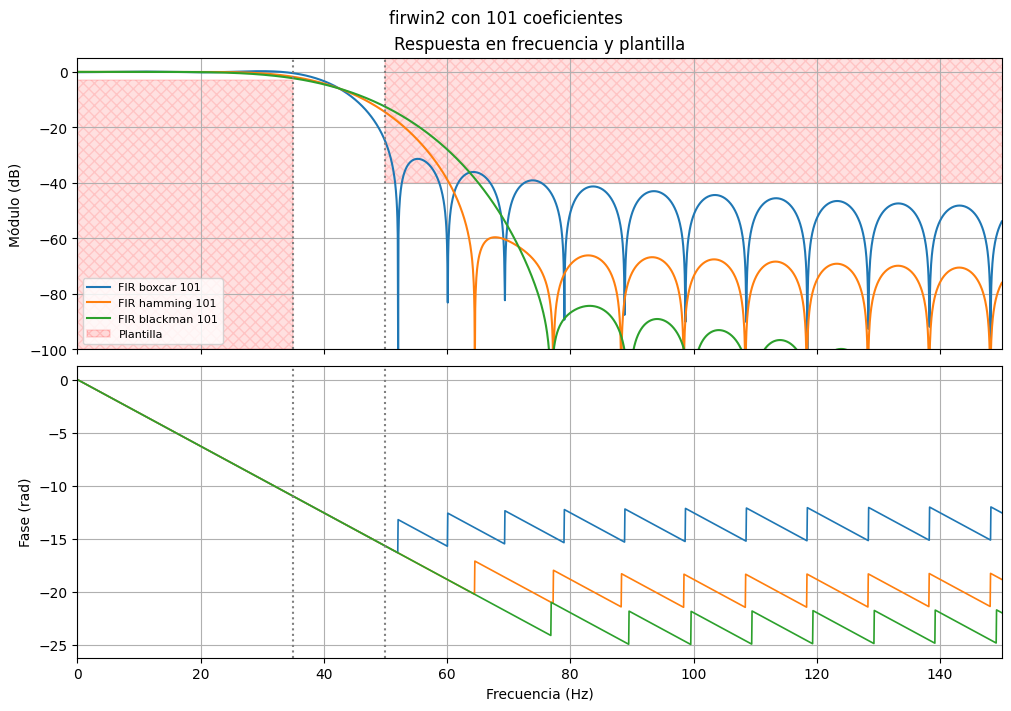

--- 101 coeficientes ---
boxcar   : peor caso banda de paso =  -0.4 dB | peor caso banda de rechazo =  -25.5 dB
hamming  : peor caso banda de paso =  -1.7 dB | peor caso banda de rechazo =  -14.6 dB
blackman : peor caso banda de paso =  -2.3 dB | peor caso banda de rechazo =  -12.6 dB


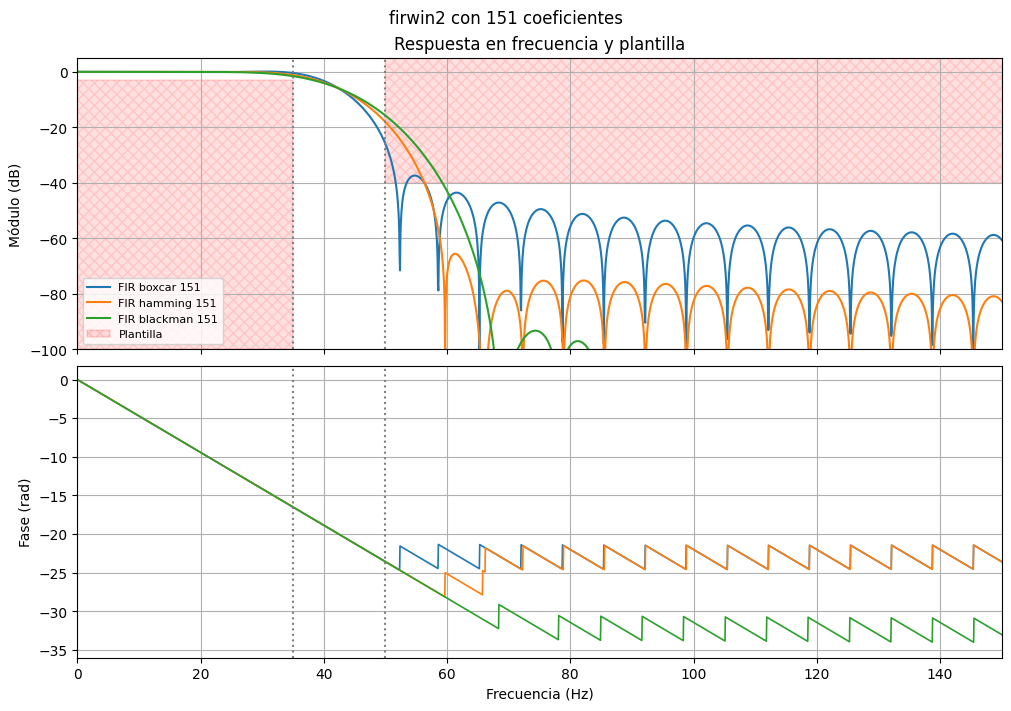

--- 151 coeficientes ---
boxcar   : peor caso banda de paso =  -0.4 dB | peor caso banda de rechazo =  -26.2 dB
hamming  : peor caso banda de paso =  -1.1 dB | peor caso banda de rechazo =  -18.2 dB
blackman : peor caso banda de paso =  -1.5 dB | peor caso banda de rechazo =  -15.8 dB


In [161]:
for taps_win in [31, 101, 151]:
    b_ventanas = disenar_ventanas(taps_win)

    fig_n_axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)
    for w, b in b_ventanas.items():
        plot_resp( calc_freq_fir(b), f'FIR {w} {taps_win}', fig_n_axes )
    plot_plantilla( fig_n_axes, ripple, att )
    fig_n_axes[0].suptitle(f'firwin2 con {taps_win} coeficientes')
    fig_n_axes[1][0].set_xlim(0, 150)
    plt.show()

    print(f'--- {taps_win} coeficientes ---')
    for w, b in b_ventanas.items():
        f, h = calc_freq_fir(b)
        m = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
        print(f'{w:9s}: peor caso banda de paso = {m[f <= wp].min():5.1f} dB | '
              f'peor caso banda de rechazo = {m[f >= ws].max():6.1f} dB')

## Estimación espectral del ECG (Welch)

Se repite la estimación espectral de la señal de corazón con el método de Welch, comparando el ECG original con las tres versiones filtradas. Se espera ver la atenuación por encima de $w_s = 50$ Hz (incluida la interferencia de línea, si existe).

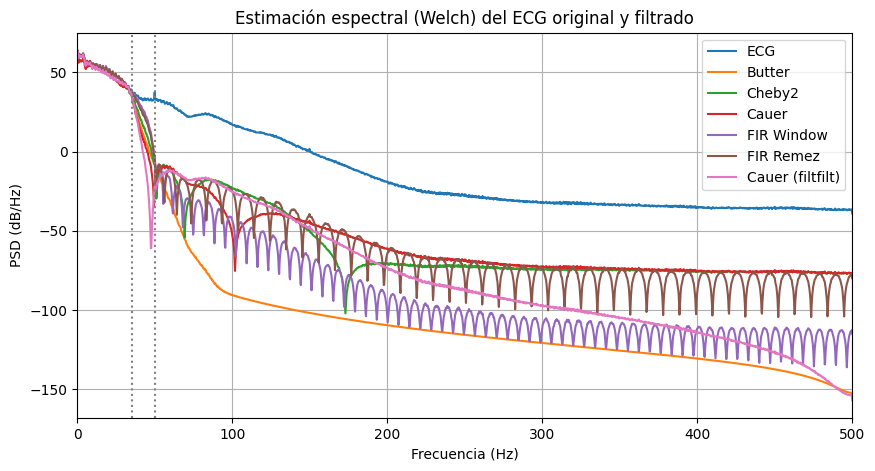

In [162]:
# Ventanas de ~4 s para tener buena resolución en frecuencia (0.25 Hz)
nperseg = 4 * fs_ecg

señales = {
    'ECG': ecg,
    'Butter': ecg_filt_butt,
    'Cheby2': ecg_filt_cheb2,
    'Cauer': ecg_filt_cauer,
    'FIR Window': ecg_filt_win,
    'FIR Remez': ecg_filt_remez,
    'Cauer (filtfilt)': ecg_filt_cauer_bi,
}

plt.figure(figsize=(10, 5))
for nombre, x in señales.items():
    f_w, psd = sig.welch(x, fs=fs_ecg, window='hann', nperseg=nperseg, detrend='linear')
    plt.plot(f_w, 10 * np.log10(psd + 1e-20), label=nombre)

plt.axvline(wp, color="gray", linestyle=":")
plt.axvline(ws, color="gray", linestyle=":")
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('PSD (dB/Hz)')
plt.title('Estimación espectral (Welch) del ECG original y filtrado')
plt.xlim(0, fs_ecg / 2)
plt.grid(True)
plt.legend()
plt.show()